# 01 Data exploration: public climate-stance corpora

**Goal.** Our training signal is English (plus one Bengali news set); the hidden test set is informal
Hindi and Bengali YouTube comments. Before training anything, this notebook checks what the
available labelled data actually contains, how well each source matches our claim, and which
artefacts would let a model score well locally without learning stance.

Target claim: *"Climate change and global warming are serious concerns."*
Labels: `favour`, `against`, `none`.

Run from the repository root after `python data_prep/build_corpus.py`.

In [1]:
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "data_prep")
from build_corpus import build
from clean_corpus import clean
from explore import (
    LABELS,
    cross_source_transfer,
    cue_rates_by_label,
    duplicates,
    hashtag_only_f1,
    log_odds_dirichlet,
    overview,
    reddit_kappa,
    script_profile,
    source_identifiability,
    vocab_overlap,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
FIG = Path("results/eda")
FIG.mkdir(parents=True, exist_ok=True)
COLORS = {"favour": "#2a9d8f", "against": "#e76f51", "none": "#8d99ae"}

corpus_path = Path("data/processed/corpus_v1.csv")
raw = pd.read_csv(corpus_path) if corpus_path.exists() else build(Path("data/raw"))
ENGLISH_GOLD = ["semeval16", "gwsd", "climate_reddit", "case2024"]
len(raw)

20467

## 1. Sources and label mapping

| source | text | original target | match to our claim | original labels → ours |
|---|---|---|---|---|
| `semeval16` | tweets (SemEval-2016 Task 6, via TweetEval) | Climate Change is a Real Concern | near-identical | favor/against/none → same |
| `gwsd` | sentences from US news (Luo et al., 2020) | global warming is a serious concern | identical | agrees/disagrees/neutral → favour/against/none |
| `climate_reddit` | Reddit comments, 2 annotators (Vaid et al., 2022) | climate change prevention | related | 1/−1/0 → favour/against/none; only rows both annotators agree on |
| `climate_reddit_pseudo` | Reddit comments labelled by the authors' model | climate change prevention | related | silver labels, kept only for inspection |
| `case2024` | tweets (ClimaConvo, CASE 2024 subtask C, train+val) | climate activism | related | support/oppose/neutral → favour/against/none |
| `dhoroni` | Bengali news articles (Wasi et al., 2024) | climate change is real and pressing | close | Positive/Negative/Neutral → favour/against/none; "Problematic" (107) dropped |

GWSD labels come from the authors' annotator model (posterior argmax) where released, otherwise
from the majority of 8 crowd votes. The ClimateStance tweets from Vaid et al. are released as IDs
only and cannot be rehydrated, so they are not included.

In [2]:
overview(raw)

,rows,lang,domain,quality,median_words,p95_words,pct_url,pct_hashtag,pct_mention,pct_emoji,pct_favour,pct_against,pct_none
source,,,,,,,,,,,,,
case2024,8845,en,tweet,gold,26.0,44.0,66.3,100.0,35.4,18.2,59.1,9.6,31.3
climate_reddit,303,en,reddit,gold,25.0,47.0,0.0,0.3,0.3,0.0,58.7,19.8,21.5
climate_reddit_pseudo,6262,en,reddit,silver,26.0,46.0,0.1,0.6,0.0,0.0,97.0,3.0,0.0
dhoroni,2193,bn,news,gold,333.0,900.0,0.2,0.3,1.3,0.0,72.3,6.2,21.4
gwsd,2300,en,news,gold,17.0,36.0,0.0,0.0,0.0,0.0,37.8,19.6,42.6
semeval16,564,en,tweet,gold,17.0,23.0,0.0,100.0,40.4,0.0,59.4,4.6,36.0


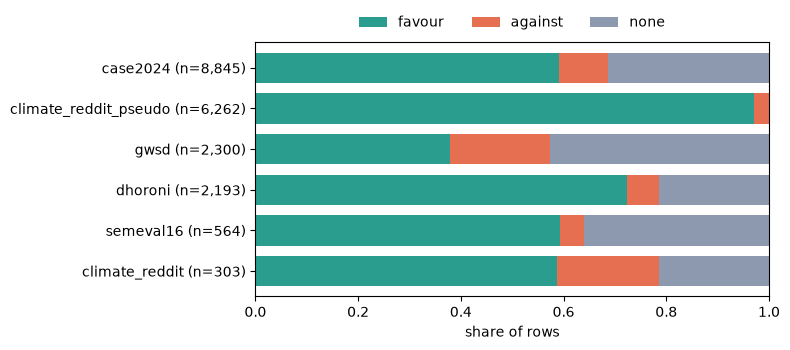

In [3]:
dist = pd.crosstab(raw["source"], raw["label"], normalize="index")[LABELS]
counts = raw["source"].value_counts()
dist = dist.loc[counts.index]
colors = [COLORS[lab] for lab in LABELS]
ax = dist.plot.barh(stacked=True, color=colors, figsize=(8, 3.6), width=0.75)
ax.set_yticklabels([f"{s} (n={counts[s]:,})" for s in dist.index])
ax.set_xlabel("share of rows")
ax.set_ylabel("")
ax.invert_yaxis()
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
plt.tight_layout()
plt.savefig(FIG / "class_distribution.png", dpi=150)

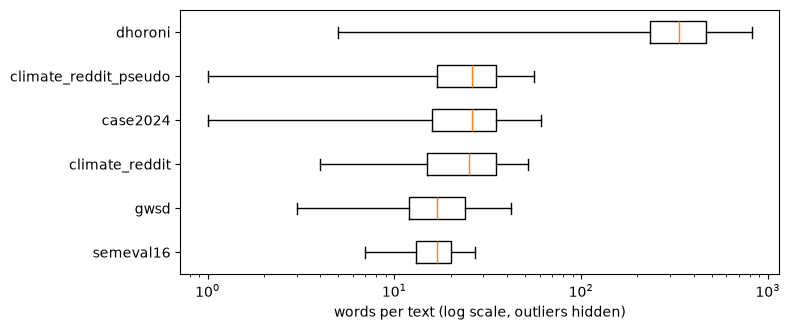

In [4]:
words = raw["text"].str.split().str.len()
median_words = raw.groupby("source")["text"].apply(lambda s: s.str.split().str.len().median())
order = median_words.sort_values().index
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.boxplot([words[raw["source"] == s] for s in order], orientation="horizontal", showfliers=False)
ax.set_yticks(range(1, len(order) + 1), order)
ax.set_xscale("log")
ax.set_xlabel("words per text (log scale, outliers hidden)")
plt.tight_layout()
plt.savefig(FIG / "length_by_source.png", dpi=150)

**Observations**

- *Against* is the minority class in every source: 4.6% of SemEval, 9.6% of CASE, 6.2% of Dhoroni,
  and at most 19.8% (Reddit). Macro F1 weights it equally with the other two classes, so it will
  dominate the score. Class weighting alone will not fix a class with only a few hundred real examples.
- Class priors differ sharply across sources (GWSD is 43% *none*, Dhoroni is 72% *favour*). The
  test-set prior is unknown; we should not assume it equals any of these.
- Lengths differ by an order of magnitude: tweets and sentences are 17–26 words, Dhoroni articles have
  a median of 333. YouTube comments are short, so Dhoroni can only be used after truncation or
  sentence-level splitting.
- Surface style is source-specific: every SemEval and CASE row has a hashtag, two-thirds of CASE rows
  have a URL, and the news and Reddit sets have almost none. YouTube comments look like none of these.

## 2. Data quality

In [5]:
duplicates(raw)

,exact_dups_within,dup_groups_with_conflicting_labels,rows_also_in_earlier_source
source,,,
case2024,1115,147,0
climate_reddit,0,0,0
climate_reddit_pseudo,67,0,21
dhoroni,0,0,0
gwsd,254,2,0
semeval16,1,0,0


In [6]:
gwsd = raw[raw["source"] == "gwsd"]
gwsd["text"].str.lower().value_counts().head(6)

text
global warming is a hoax.                                                                                                                               50
alarming levels of sea level rise are predicted to threaten florida over the next decades.                                                              50
over the past several years, the united states has seen an increase in business growth that has counteracted the lingering effects of the recession.    50
global warming is happening and it will be dangerous to human health and welfare.                                                                       50
some icebergs are cute.                                                                                                                                 50
there is no solid evidence of global warming.                                                                                                            2
Name: count, dtype: int64

In [7]:
case = raw[raw["source"] == "case2024"]
template = case["text"].str.lower().str.contains("you've been fooled", regex=False)
print(f"CASE rows built on one spam template: {template.sum()} "
      f"({template.mean():.1%} of CASE), "
      f"labels: {case.loc[template, 'label'].value_counts().to_dict()}")
print(f"share of all CASE 'against' rows that are this template: "
      f"{template[case['label'] == 'against'].mean():.1%}")

CASE rows built on one spam template: 587 (6.6% of CASE), labels: {'against': 586, 'favour': 1}
share of all CASE 'against' rows that are this template: 68.7%


ClimateReddit Cohen's kappa: 0.864 (agreement on 303 of 329)
GWSD sentences with confidence < 0.6: 9.4%


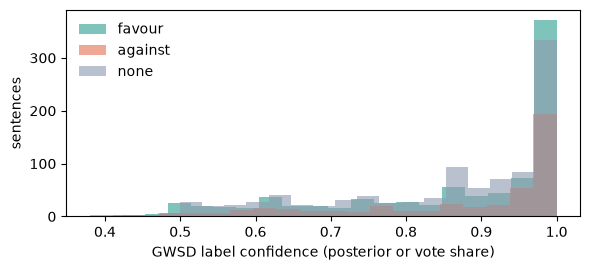

In [8]:
a1 = pd.read_csv("data/raw/reddit_a1.tsv", sep="\t")
a2 = pd.read_csv("data/raw/reddit_a2.tsv", sep="\t")
print(f"ClimateReddit Cohen's kappa: {reddit_kappa(a1['opinion-label'], a2['opinion-label']):.3f} "
      f"(agreement on {(a1['opinion-label'] == a2['opinion-label']).sum()} of {len(a1)})")

fig, ax = plt.subplots(figsize=(6, 2.8))
for label in LABELS:
    ax.hist(gwsd.loc[gwsd["label"] == label, "agreement"], bins=20, alpha=0.6,
            label=label, color=COLORS[label])
ax.set_xlabel("GWSD label confidence (posterior or vote share)")
ax.set_ylabel("sentences")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG / "gwsd_confidence.png", dpi=150)
print(f"GWSD sentences with confidence < 0.6: {(gwsd['agreement'] < 0.6).mean():.1%}")

**Observations**

- **GWSD contains crowd-sourcing screening items.** Five sentences, such as "Global warming is a hoax."
  and "Some icebergs are cute.", appear 50 times each (250 rows). Left in, they teach the model
  that words like *florida*, *icebergs* and *cute* are class markers, and they leak across any random
  train/validation split.
- **69% of CASE *against* rows (587 of 853) are one repeated spam tweet** ("You've been fooled…")
  with shuffled hashtags. After removing it and other duplicates, only 219 CASE *against* rows remain.
- CASE also has 1,115 within-source exact duplicates and 147 duplicate groups whose copies carry
  different labels, a direct measure of label noise.
- Reading a random sample of the remaining CASE *against* rows shows several that express concern
  about climate (attacks on fossil-fuel lobbying, calls to invest in renewables). Their target is
  *activism*, not the claim, so CASE *against* does not mean "climate change is not serious".
  This needs a manual check on ~100 rows before CASE *against* is used for training.
- Annotation quality where we can measure it is good: ClimateReddit annotators reach κ = 0.86, and
  most GWSD labels have confidence above 0.75. Around 9% of GWSD labels are low-confidence (< 0.6).
- The pseudo-labelled Reddit set is 97% *favour* and has no *none* rows, so it would only add bias.

## 3. Cleaning

Rules applied by `data_prep/clean_corpus.py`, in this order: drop silver labels, drop the CASE spam
template, drop English rows with fewer than 3 words once hashtags/URLs/mentions are removed, drop
every copy of a text with conflicting labels, then keep one copy of each remaining duplicate.
The SemEval collection hashtag `#SemST` (present in 100% of SemEval tweets) is removed from the text.

In [9]:
df, removed = clean(raw)
removed

,silver_labels,spam_template,no_content,conflicting_duplicates,duplicates
source,,,,,
case2024,0,587,62,501,236
climate_reddit_pseudo,6262,0,0,0,0
gwsd,0,0,0,52,204
semeval16,0,0,1,0,1


In [10]:
pd.crosstab(df["source"], df["label"], margins=True)

label,against,favour,none,All
source,,,,
case2024,219,4788,2452,7459
climate_reddit,60,178,65,303
dhoroni,137,1586,470,2193
gwsd,397,774,873,2044
semeval16,26,334,202,562
All,839,7660,4062,12561


After cleaning: 12,561 rows. The three sources whose target matches the claim (`tier == "core"`:
SemEval, GWSD, ClimateReddit) give 2,909 rows with 483 *against*. CASE and Dhoroni are kept as an
`auxiliary` tier so every experiment can include or exclude them.

## 4. What distinguishes the classes (core tier)

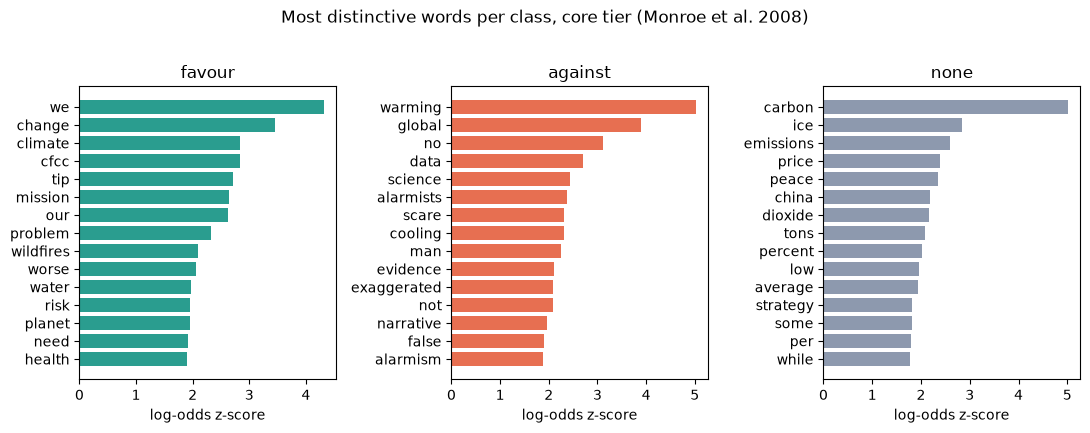

In [11]:
core = df[df["tier"] == "core"]
fig, axes = plt.subplots(1, 3, figsize=(11, 4.2))
for ax, label in zip(axes, LABELS, strict=True):
    top = log_odds_dirichlet(core, label, top=15, min_count=3).iloc[::-1]
    ax.barh(top["word"], top["z"], color=COLORS[label])
    ax.set_title(label)
    ax.set_xlabel("log-odds z-score")
plt.suptitle("Most distinctive words per class, core tier (Monroe et al. 2008)", y=1.02)
plt.tight_layout()
plt.savefig(FIG / "log_odds_core.png", dpi=150, bbox_inches="tight")

In [12]:
cue_rates_by_label(core).drop(columns="has_url")

,has_negation,is_question,has_exclaim,has_we
label,,,,
favour,16.0,5.1,3.0,20.1
against,27.1,2.5,1.4,9.3
none,14.9,4.0,3.3,9.7


In [13]:
pd.DataFrame({s: cue_rates_by_label(df[df["source"] == s])["has_negation"] for s in ENGLISH_GOLD})

,semeval16,gwsd,climate_reddit,case2024
label,,,,
favour,18.9,10.7,33.7,19.2
against,19.2,27.5,28.3,25.6
none,17.8,12.5,38.5,14.9


**Observations**

- *Against* is lexically coherent once the artefacts are gone: *hoax*-type vocabulary such as
  *alarmists, scare, exaggerated, narrative, false, alarmism, cooling, evidence*. It also argues about
  *science* and *data*, so topic words alone cannot separate it from *favour*.
- *Against* is led by *warming* and *global*, while *favour* uses *climate* and *change*. Skeptical
  writers say "global warming", supporters say "climate change", a framing difference also reported
  in survey research. Hindi and Bengali YouTube comments often borrow "global warming" as an English
  loanword, so a model that has learned this as an *against* cue could misread pro-climate comments.
  This is a concrete error hypothesis to test.
- *Favour* uses collective, action-oriented language (*we, our, need, problem, risk, planet, health*)
  and mentions impacts (*wildfires, water, worse*).
- *None* is dominated by factual and economic vocabulary (*carbon, emissions, price, tons, percent*).
  On-topic but neutral text is common, which makes *none* vs *favour* the hard boundary in practice.
- Negation is more frequent in *against* overall (27% vs 15–16%), but the pattern depends on the
  source: it holds for GWSD and CASE, disappears in SemEval (about 19% in every class), and reverses in
  ClimateReddit, where *against* has the *lowest* negation rate. **Negation is not a reliable stance
  cue across domains**, which is why the challenge set must test it explicitly.

## 5. Domain shift and shortcuts

In [14]:
overlap = vocab_overlap(df, ENGLISH_GOLD)
print(f"source identifiability from text (TF-IDF + LR, 4 sources, chance = 0.25): "
      f"{source_identifiability(df, ENGLISH_GOLD):.2f}")
overlap

source identifiability from text (TF-IDF + LR, 4 sources, chance = 0.25): 0.85


,semeval16,gwsd,climate_reddit,case2024
semeval16,1.00,0.23,0.22,0.26
gwsd,0.23,1.00,0.26,0.30
climate_reddit,0.22,0.26,1.00,0.26
case2024,0.26,0.30,0.26,1.00


,semeval16,gwsd,climate_reddit,case2024
train \ test,,,,
semeval16,0.559,0.367,0.502,0.319
gwsd,0.429,0.607,0.448,0.350
climate_reddit,0.311,0.329,0.401,0.339
case2024,0.306,0.321,0.320,0.458


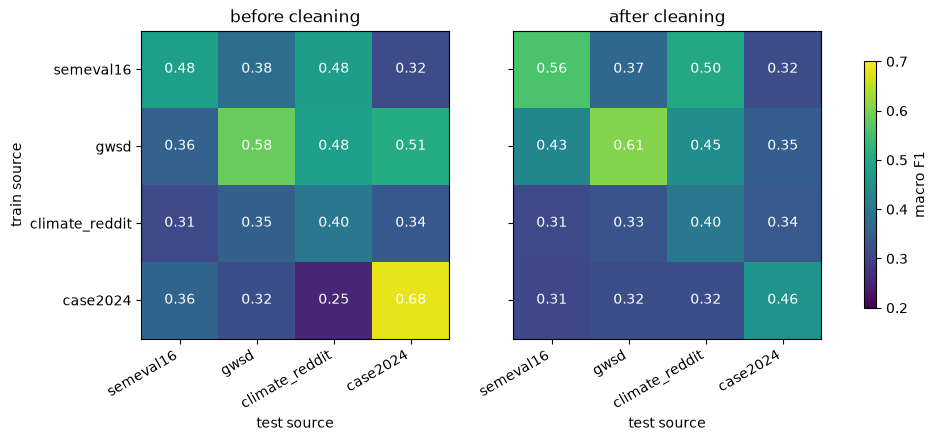

In [15]:
before = cross_source_transfer(raw, ENGLISH_GOLD)
after = cross_source_transfer(df, ENGLISH_GOLD)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
titles = ["before cleaning", "after cleaning"]
for ax, table, title in zip(axes, [before, after], titles, strict=True):
    im = ax.imshow(table.values.astype(float), vmin=0.2, vmax=0.7, cmap="viridis")
    ax.set_xticks(range(4), table.columns, rotation=30, ha="right")
    ax.set_yticks(range(4), table.index)
    ax.set_xlabel("test source")
    ax.set_title(title)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{table.iat[i, j]:.2f}", ha="center", va="center", color="white")
axes[0].set_ylabel("train source")
axes[1].set_yticklabels([])
fig.colorbar(im, ax=axes, shrink=0.8, label="macro F1")
plt.savefig(FIG / "cross_source_transfer.png", dpi=150, bbox_inches="tight")
after

In [16]:
for name, data in [("before cleaning", raw), ("after cleaning", df)]:
    tags, rest = hashtag_only_f1(data, "case2024")
    print(f"CASE {name}: hashtags only = {tags:.3f} macro F1, text without hashtags = {rest:.3f}")

CASE before cleaning: hashtags only = 0.603 macro F1, text without hashtags = 0.666


CASE after cleaning: hashtags only = 0.356 macro F1, text without hashtags = 0.480


**Observations**

- The four English sources share only 22–30% of their 3,000 most frequent words, and a bag-of-words
  classifier identifies the source of a text 85% of the time (chance is 25%). Each corpus is its own
  domain.
- In-domain TF-IDF baselines reach 0.40–0.61 macro F1; across sources they fall to 0.31–0.50. A model
  trained on any single source loses roughly a third of its score on another *English* source, before
  any change of language or platform.
- **Cleaning lowered CASE's in-domain score from 0.68 to 0.46.** The higher number came from
  memorising the spam template, not from understanding stance. This is the same kind of inflated
  local score that separated internal validation from official test results in prior AISoMe work.
- Before cleaning, hashtags alone gave 0.60 macro F1 on CASE, close to the full text. After cleaning,
  hashtags alone fall to 0.36. Hashtags remain a shortcut worth removing or masking during training,
  since YouTube comments rarely use them.
- The claim-aligned sources transfer best (SemEval → Reddit 0.50, GWSD → Reddit 0.45); models trained
  on CASE transfer worst. GWSD → CASE dropped from 0.51 to 0.35 after cleaning, which shows that part
  of the earlier score came from the CASE test split being full of the same template.

## 6. Bengali auxiliary data (Dhoroni)

In [17]:
dh = df[df["source"] == "dhoroni"]
profile = script_profile(dh["text"]).mean().round(3)
lengths = dh["text"].str.split().str.len().describe()[["25%", "50%", "75%", "max"]]
print("script share:", profile.to_dict())
print("words per article:", lengths.to_dict())
dh["label"].value_counts(normalize=True).round(3)

script share: {'bengali': 0.999, 'devanagari': 0.0, 'latin': 0.001}
words per article: {'25%': 235.0, '50%': 333.0, '75%': 469.0, 'max': 3213.0}


label
favour     0.723
none       0.214
against    0.062
Name: proportion, dtype: float64

**Observations**

- Dhoroni is almost entirely Bengali script (99.9%), formal news register, and long (median 333
  words). It is the only native-language labelled climate-stance data available.
- Its stance is about the *article*, and articles mostly report climate impacts, so it is 72%
  *favour*. Useful for adapting the encoder to Bengali climate vocabulary; not a stand-in for
  comment-level stance. Candidate uses: domain-adaptive pretraining, or headline/lead-sentence
  training examples in the auxiliary tier.

## 7. Implications for modelling

1. **There is no Hindi data and no YouTube data in any public labelled set.** Every source differs from
   the test set in language, platform, or both. A hand-labelled native Hindi/Bengali YouTube dev set
   is the only trustworthy model-selection signal; English validation scores should be treated as
   sanity checks only.
2. **Train on the core tier first** (SemEval + GWSD + ClimateReddit, 2,909 rows, targets matching the
   claim). Add CASE and Dhoroni one at a time as ablations, never by default.
3. **Do not use CASE *against* labels until they are spot-checked**, because they reflect opposition to
   activism rather than to the claim, and most of them were spam.
4. **Remove platform artefacts** (hashtags, URLs, mentions, `#SemST`) so the model cannot rely on
   features absent from YouTube comments.
5. ***Against* is scarce (483 core rows).** Targeted augmentation of *against* (paraphrase,
   translation, LLM-generated examples checked by hand) is likely to move macro F1 more than any
   architecture change.
6. Group-aware splits (by normalised text) are required to avoid duplicate leakage; random splits on the
   raw files would overstate results.